## Random Forest Forecasting Template
### **Enterprise-Ready | Version 2.0**
# 
### Quick Start
#### 1. **Section 0**: Preview your data to see available columns
#### 2. **Section 1**: Update CONFIG with your settings
#### 3. **Run All**: Execute all cells
#### 4. **Review**: Check results in Section 11

In [128]:
# 0. Data Preview

import pandas as pd
import numpy as np
from pathlib import Path

# =============================================================================
# UPDATE THESE TWO LINES TO POINT TO YOUR DATA
# =============================================================================

PREVIEW_PATH = '../data/processed/'
PREVIEW_FILE = 'weather_history_hourly.csv'  # .csv, .xlsx, .parquet

# =============================================================================

file_path = Path(PREVIEW_PATH) / PREVIEW_FILE

if file_path.exists():
    ext = file_path.suffix.lower()
    if ext == '.csv':
        preview_df = pd.read_csv(file_path, nrows=1000)
    elif ext in ['.xlsx', '.xls']:
        preview_df = pd.read_excel(file_path, nrows=1000)
    elif ext == '.parquet':
        preview_df = pd.read_parquet(file_path)
    
    print(f"File: {PREVIEW_FILE} | {preview_df.shape[0]:,} rows x {preview_df.shape[1]} columns\n")
    print(f"{'Column':<35} {'Type':<12} {'Sample'}")
    print("-" * 65)
    for col in preview_df.columns:
        dtype = str(preview_df[col].dtype)[:10]
        sample = str(preview_df[col].dropna().iloc[0])[:30] if len(preview_df[col].dropna()) > 0 else 'N/A'
        print(f"{col:<35} {dtype:<12} {sample}")
    
    print(f"\nNumeric (target_col):     {preview_df.select_dtypes(include=['int64', 'float64']).columns.tolist()[:5]}")
    print(f"Categorical (encode_cols): {preview_df.select_dtypes(include=['object']).columns.tolist()[:5]}")
else:
    print(f"File not found: {file_path}")

File: weather_history_hourly.csv | 1,000 rows x 38 columns

Column                              Type         Sample
-----------------------------------------------------------------
datetime                            object       2020-01-01 00:00:00
temperature_2m                      float64      6.2
apparent_temperature                float64      3.8
dewpoint_2m                         float64      5.9
relative_humidity_2m                int64        98
pressure_msl                        float64      1030.8
precipitation                       float64      0.0
rain                                float64      0.0
snowfall                            float64      0.0
windspeed_10m                       float64      10.0
winddirection_10m                   int64        116
cloudcover                          int64        100
weathercode                         int64        3
location                            object       Birmingham
country                             object       UK


In [129]:
# 1. Configuration

CONFIG = {
    'data_path': '../data/processed/',
    'file_name': 'weather_history_hourly.csv',
    'column_mapping': {},
    
    'datetime_col': 'datetime',
    'date_format': None,
    'output_date_format': '%d-%b-%Y',
    'data_frequency': 'hourly',
    
    'target_col': 'temperature_2m',
    'calculated_target': None,
    'calculated_target_name': 'calculated_value',
    
    'feature_cols': [
        'hour', 'month', 'day_of_year',
        'hour_sin', 'hour_cos', 'month_sin', 'month_cos',
        'location_encoded',
        'target_lag_1', 'target_lag_2', 'target_lag_3',
        'target_lag_4',
        'relative_humidity_2m', 'pressure_msl',
    ],
    'additional_features': [],
    'encode_cols': ['location'],
    
    'lag_features': {
        'target_lag_1': 1,      # 1 hour
        'target_lag_2': 24,     # 1 day
        'target_lag_3': 168,    # 1 week
        'target_lag_4': 720,    # 1 month
    },
    'lag_source_col': 'auto',
    'lag_group_col': ['location'],
    
    'add_seasonality': True,
    'seasons': {
        'is_winter': [12, 1, 2],
        'is_spring': [3, 4, 5],
        'is_summer': [6, 7, 8],
        'is_autumn': [9, 10, 11],
    },
    
    'analysis_group_cols': ['location'],
    
    'split_type': 'date',
    'test_days': 7,             # 7 days = ~840 hourly rows
    'test_ratio': 0.2,
    'test_rows': 1000,
    
    'generate_future_forecast': True,
    'forecast_horizon': 7,
    'forecast_unit': 'days',
    
    'output_aggregation': 'raw',
    'output_path': '../data/processed/',
    'output_file': 'rf_predictions.csv',
    'future_forecast_file': 'rf_future_forecast.csv',
    'output_format': 'csv',
    
    'model_params': {
        'n_estimators': 100,
        'max_depth': 10,
        'min_samples_split': 10,
        'min_samples_leaf': 5,
        'max_features': 'sqrt',
        'random_state': 42,
        'n_jobs': -1,
    },
    
    'missing_value_strategy': 'mean',
}


In [130]:
# 2. Setup

import pandas as pd
import numpy as np
from datetime import datetime, timedelta
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')

try:
    from dateutil.relativedelta import relativedelta
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "python-dateutil", "-q"])
    from dateutil.relativedelta import relativedelta

from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.style.use('seaborn-v0_8-whitegrid')

RESULTS = {}
ENCODERS = {}

In [131]:
# 3. Load Data

def load_data(config):
    file_path = Path(config['data_path']) / config['file_name']
    ext = file_path.suffix.lower()
    
    if ext == '.csv':
        df = pd.read_csv(file_path)
    elif ext in ['.xlsx', '.xls']:
        df = pd.read_excel(file_path)
    elif ext == '.parquet':
        df = pd.read_parquet(file_path)
    else:
        raise ValueError(f"Unsupported format: {ext}")
    
    if config['column_mapping']:
        df = df.rename(columns=config['column_mapping'])
    
    # Convert datetime
    if config['datetime_col'] in df.columns:
        if config['date_format']:
            df[config['datetime_col']] = pd.to_datetime(df[config['datetime_col']], format=config['date_format'], errors='coerce')
        else:
            df[config['datetime_col']] = pd.to_datetime(df[config['datetime_col']], dayfirst=True, infer_datetime_format=True, errors='coerce')
    
    # Convert integer columns to float to handle NaN
    for col in df.columns:
        if df[col].dtype in ['int64', 'int32']:
            df[col] = df[col].astype(float)
    
    df = df.sort_values(config['datetime_col']).reset_index(drop=True)
    
    return df

df = load_data(CONFIG)

In [132]:
# 4. Setup Target

def setup_target(df, config):
    if config['calculated_target']:
        try:
            df[config['calculated_target_name']] = df.eval(config['calculated_target'])
            target_col = config['calculated_target_name']
        except:
            target_col = config['target_col']
    else:
        target_col = config['target_col']
    
    lag_source = target_col if config['lag_source_col'] == 'auto' else config['lag_source_col']
    return df, target_col, lag_source

df, target_col, lag_source = setup_target(df, CONFIG)

In [133]:
# 5. Feature Engineering

def create_features(df, config, lag_source):
    global ENCODERS
    
    # Time features
    if config['datetime_col'] in df.columns:
        dt = df[config['datetime_col']]
        df['hour'] = dt.dt.hour
        df['day'] = dt.dt.day
        df['month'] = dt.dt.month
        df['year'] = dt.dt.year
        df['day_of_week'] = dt.dt.dayofweek
        df['day_of_year'] = dt.dt.dayofyear
        df['week_of_year'] = dt.dt.isocalendar().week.astype(float).fillna(0).astype(int)
        df['quarter'] = dt.dt.quarter
        df['is_weekend'] = df['day_of_week'].isin([5, 6]).astype(int)
        
        # Cyclical
        df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24)
        df['hour_cos'] = np.cos(2 * np.pi * df['hour'] / 24)
        df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12)
        df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12)
        df['day_of_week_sin'] = np.sin(2 * np.pi * df['day_of_week'] / 7)
        df['day_of_week_cos'] = np.cos(2 * np.pi * df['day_of_week'] / 7)
        df['quarter_sin'] = np.sin(2 * np.pi * df['quarter'] / 4)
        df['quarter_cos'] = np.cos(2 * np.pi * df['quarter'] / 4)
    
    # Seasonality
    if config['add_seasonality'] and 'month' in df.columns:
        for season_name, months in config['seasons'].items():
            df[season_name] = df['month'].isin(months).astype(int)
        
        def get_season(m):
            if m in [12, 1, 2]: return 0
            elif m in [3, 4, 5]: return 1
            elif m in [6, 7, 8]: return 2
            else: return 3
        
        df['season'] = df['month'].apply(get_season)
        df['season_sin'] = np.sin(2 * np.pi * df['season'] / 4)
        df['season_cos'] = np.cos(2 * np.pi * df['season'] / 4)
    
    # Lag features
    if config['lag_features']:
        group_cols = config['lag_group_col']
        if group_cols and not isinstance(group_cols, list):
            group_cols = [group_cols]
        
        valid_groups = group_cols and all(col in df.columns for col in group_cols)
        
        for lag_name, lag_periods in config['lag_features'].items():
            if lag_name not in df.columns:
                if valid_groups:
                    df[lag_name] = df.groupby(group_cols)[lag_source].shift(lag_periods)
                else:
                    df[lag_name] = df[lag_source].shift(lag_periods)
    
    # Encode categoricals
    for col in config['encode_cols']:
        if col in df.columns:
            le = LabelEncoder()
            df[f'{col}_encoded'] = le.fit_transform(df[col].astype(str))
            ENCODERS[col] = le
    
    return df

df = create_features(df, CONFIG, lag_source)

In [134]:
# 6. Prepare and Split

def prepare_and_split(df, config, target_col):
    # Prepare features
    feature_cols = config['feature_cols'].copy()
    for col in config.get('additional_features', []):
        if col in df.columns and col not in feature_cols:
            feature_cols.append(col)
    feature_cols = [col for col in feature_cols if col in df.columns]
    
    # Handle missing
    lag_cols = [c for c in config['lag_features'].keys() if c in df.columns]
    if lag_cols:
        df = df.dropna(subset=lag_cols)
    
    strategy = config.get('missing_value_strategy', 'mean')
    for col in feature_cols:
        if col in df.columns and df[col].isnull().any():
            if strategy == 'mean':
                df[col] = df[col].fillna(df[col].mean())
            elif strategy == 'median':
                df[col] = df[col].fillna(df[col].median())
            elif strategy == 'zero':
                df[col] = df[col].fillna(0)
    
    # Split
    if config['split_type'] == 'date':
        df['date'] = df[config['datetime_col']].dt.date
        max_date = pd.to_datetime(df['date']).max()
        split_date = max_date - timedelta(days=config['test_days'])
        train = df[pd.to_datetime(df['date']) <= split_date].copy()
        test = df[pd.to_datetime(df['date']) > split_date].copy()
    elif config['split_type'] == 'ratio':
        split_idx = int(len(df) * (1 - config['test_ratio']))
        train, test = df.iloc[:split_idx].copy(), df.iloc[split_idx:].copy()
    else:
        train, test = df.iloc[:-config['test_rows']].copy(), df.iloc[-config['test_rows']:].copy()
    
    return df, train, test, feature_cols

df, train, test, feature_cols = prepare_and_split(df, CONFIG, target_col)

X_train, y_train = train[feature_cols], train[target_col]
X_test, y_test = test[feature_cols], test[target_col]

In [135]:
# 7. Train Model

model = RandomForestRegressor(**CONFIG['model_params'])
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamp

In [136]:
# 8. Evaluate

y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

RESULTS['metrics'] = {
    'train_mae': mean_absolute_error(y_train, y_pred_train),
    'train_rmse': np.sqrt(mean_squared_error(y_train, y_pred_train)),
    'train_r2': r2_score(y_train, y_pred_train),
    'test_mae': mean_absolute_error(y_test, y_pred_test),
    'test_rmse': np.sqrt(mean_squared_error(y_test, y_pred_test)),
    'test_r2': r2_score(y_test, y_pred_test),
}

RESULTS['importance'] = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': model.feature_importances_
}).sort_values('Importance', ascending=False)

In [137]:
# 9. Test Predictions

# %%
test['predicted'] = y_pred_test
test['error'] = test['predicted'] - test[target_col]

if CONFIG['datetime_col'] in test.columns:
    test['date_formatted'] = test[CONFIG['datetime_col']].dt.strftime(CONFIG['output_date_format'])

RESULTS['test_predictions'] = test

In [138]:
# 10. Future Forecast

if CONFIG['generate_future_forecast']:
    
    latest_date = df[CONFIG['datetime_col']].max()
    
    def get_future_date(base, n, unit):
        if unit == 'hours': return base + timedelta(hours=n)
        elif unit == 'days': return base + timedelta(days=n)
        elif unit == 'weeks': return base + timedelta(weeks=n)
        elif unit == 'months': return base + relativedelta(months=n)
        elif unit == 'quarters': return base + relativedelta(months=n*3)
        elif unit == 'years': return base + relativedelta(years=n)
    
    group_cols = CONFIG['lag_group_col']
    if group_cols and not isinstance(group_cols, list):
        group_cols = [group_cols]
    
    groups = df[group_cols].drop_duplicates().to_dict('records') if group_cols and all(c in df.columns for c in group_cols) else [{}]
    future_dates = [get_future_date(latest_date, i, CONFIG['forecast_unit']) for i in range(1, CONFIG['forecast_horizon'] + 1)]
    max_lag = max(CONFIG['lag_features'].values()) if CONFIG['lag_features'] else 1
    
    future_rows = []
    
    for group in groups:
        if group:
            mask = np.ones(len(df), dtype=bool)
            for col, val in group.items():
                mask &= (df[col].values == val)
            group_history = df.loc[mask].sort_values(CONFIG['datetime_col']).tail(max_lag).copy()
        else:
            group_history = df.sort_values(CONFIG['datetime_col']).tail(max_lag).copy()
        
        for future_date in future_dates:
            row = {'datetime': future_date}
            row.update(group)
            
            row['hour'], row['day'], row['month'], row['year'] = future_date.hour, future_date.day, future_date.month, future_date.year
            row['day_of_week'], row['day_of_year'] = future_date.weekday(), future_date.timetuple().tm_yday
            row['week_of_year'], row['quarter'] = future_date.isocalendar()[1], (future_date.month - 1) // 3 + 1
            row['is_weekend'] = 1 if future_date.weekday() in [5, 6] else 0
            
            row['hour_sin'], row['hour_cos'] = np.sin(2 * np.pi * row['hour'] / 24), np.cos(2 * np.pi * row['hour'] / 24)
            row['month_sin'], row['month_cos'] = np.sin(2 * np.pi * row['month'] / 12), np.cos(2 * np.pi * row['month'] / 12)
            row['day_of_week_sin'], row['day_of_week_cos'] = np.sin(2 * np.pi * row['day_of_week'] / 7), np.cos(2 * np.pi * row['day_of_week'] / 7)
            row['quarter_sin'], row['quarter_cos'] = np.sin(2 * np.pi * row['quarter'] / 4), np.cos(2 * np.pi * row['quarter'] / 4)
            
            if CONFIG['add_seasonality']:
                for season_name, months in CONFIG['seasons'].items():
                    row[season_name] = 1 if row['month'] in months else 0
                for idx, (sn, sm) in enumerate(CONFIG['seasons'].items()):
                    if row['month'] in sm:
                        row['season'] = idx
                        break
                row['season_sin'], row['season_cos'] = np.sin(2 * np.pi * row.get('season', 0) / 4), np.cos(2 * np.pi * row.get('season', 0) / 4)
            
            for col in CONFIG['encode_cols']:
                if col in group and col in ENCODERS:
                    row[f'{col}_encoded'] = ENCODERS[col].transform([group[col]])[0]
            
            for lag_name, lag_periods in CONFIG['lag_features'].items():
                row[lag_name] = group_history[target_col].iloc[-lag_periods] if len(group_history) >= lag_periods else (group_history[target_col].iloc[-1] if len(group_history) > 0 else 0)
            
            X_future = pd.DataFrame([row])
            for col in feature_cols:
                if col not in X_future.columns:
                    X_future[col] = 0
            
            prediction = model.predict(X_future[feature_cols])[0]
            row['predicted'] = prediction
            future_rows.append(row)
            
            new_row = group_history.iloc[-1:].copy()
            new_row[CONFIG['datetime_col']] = future_date
            new_row[target_col] = prediction
            group_history = pd.concat([group_history, new_row]).tail(max_lag)
    
    future_forecast = pd.DataFrame(future_rows)
    future_forecast['date_formatted'] = pd.to_datetime(future_forecast['datetime']).dt.strftime(CONFIG['output_date_format'])
    RESULTS['future_forecast'] = future_forecast


In [139]:
# 11. Results

print("=" * 70)
print("RESULTS")
print("=" * 70)

print(f"\nTarget: {target_col}")
print(f"Train: {len(train):,} | Test: {len(test):,} | Features: {len(feature_cols)}")

print(f"\nPerformance:")
print(f"  {'Metric':<8} {'Train':<12} {'Test':<12}")
print(f"  {'-'*32}")
print(f"  {'MAE':<8} {RESULTS['metrics']['train_mae']:<12.3f} {RESULTS['metrics']['test_mae']:<12.3f}")
print(f"  {'RMSE':<8} {RESULTS['metrics']['train_rmse']:<12.3f} {RESULTS['metrics']['test_rmse']:<12.3f}")
print(f"  {'R2':<8} {RESULTS['metrics']['train_r2']:<12.3f} {RESULTS['metrics']['test_r2']:<12.3f}")

print(f"\nTop Features:")
for _, row in RESULTS['importance'].head(5).iterrows():
    print(f"  {row['Feature']:<25} {row['Importance']:.3f}")

if CONFIG['generate_future_forecast']:
    fc = RESULTS['future_forecast']
    print(f"\nFuture Forecast: {CONFIG['forecast_horizon']} {CONFIG['forecast_unit']}")
    print(f"  Range: {fc['predicted'].min():.2f} to {fc['predicted'].max():.2f} | Mean: {fc['predicted'].mean():.2f}")

if CONFIG['analysis_group_cols'] and all(c in test.columns for c in CONFIG['analysis_group_cols']):
    print(f"\nBy {', '.join(CONFIG['analysis_group_cols'])}:")
    for name, grp in test.groupby(CONFIG['analysis_group_cols']):
        mae = mean_absolute_error(grp[target_col], grp['predicted'])
        r2 = r2_score(grp[target_col], grp['predicted']) if len(grp) > 1 else np.nan
        print(f"  {name}: MAE={mae:.3f}, R2={r2:.3f}")

RESULTS

Target: temperature_2m
Train: 100,320 | Test: 120 | Features: 14

Performance:
  Metric   Train        Test        
  --------------------------------
  MAE      0.851        2.641       
  RMSE     1.237        2.762       
  R2       0.956        -3.993      

Top Features:
  target_lag_1              0.535
  target_lag_2              0.171
  target_lag_4              0.095
  relative_humidity_2m      0.067
  target_lag_3              0.048

Future Forecast: 7 days
  Range: 5.61 to 10.42 | Mean: 8.41

By location:
  ('Birmingham',): MAE=2.909, R2=-8.656
  ('Cardiff',): MAE=2.203, R2=-0.808
  ('Edinburgh',): MAE=3.128, R2=-23.203
  ('London',): MAE=2.345, R2=-6.014
  ('Manchester',): MAE=2.619, R2=-7.350


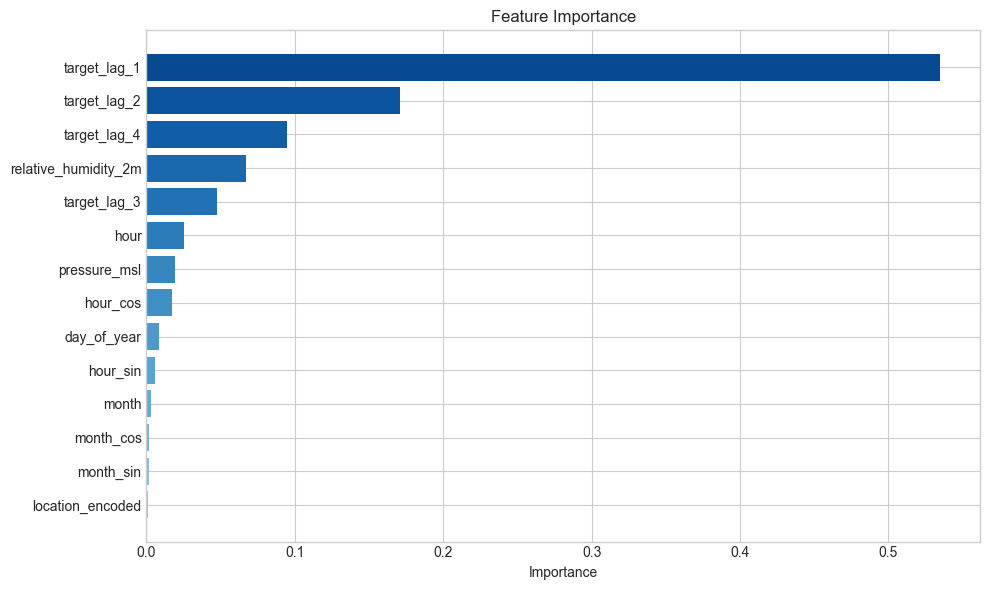

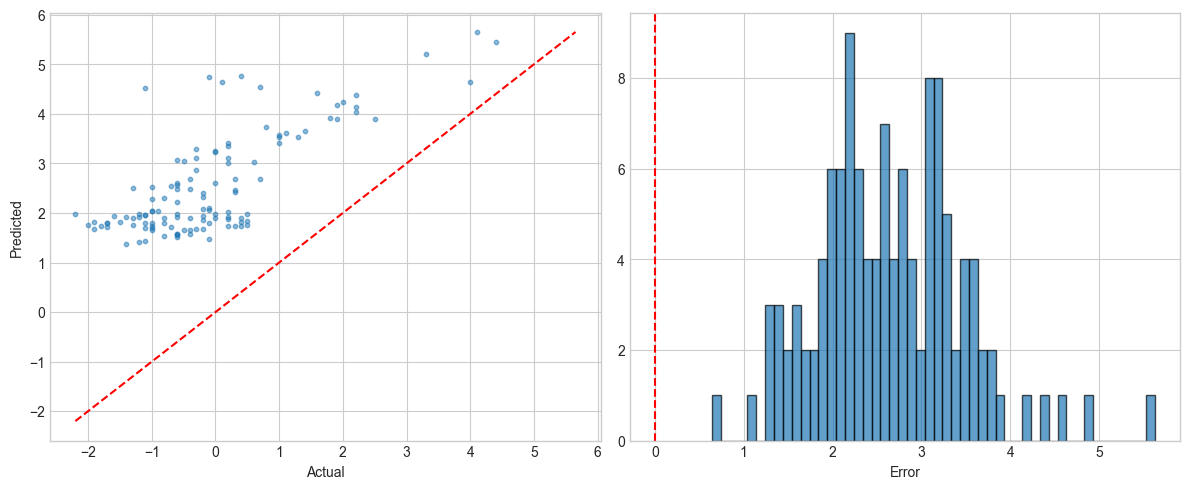

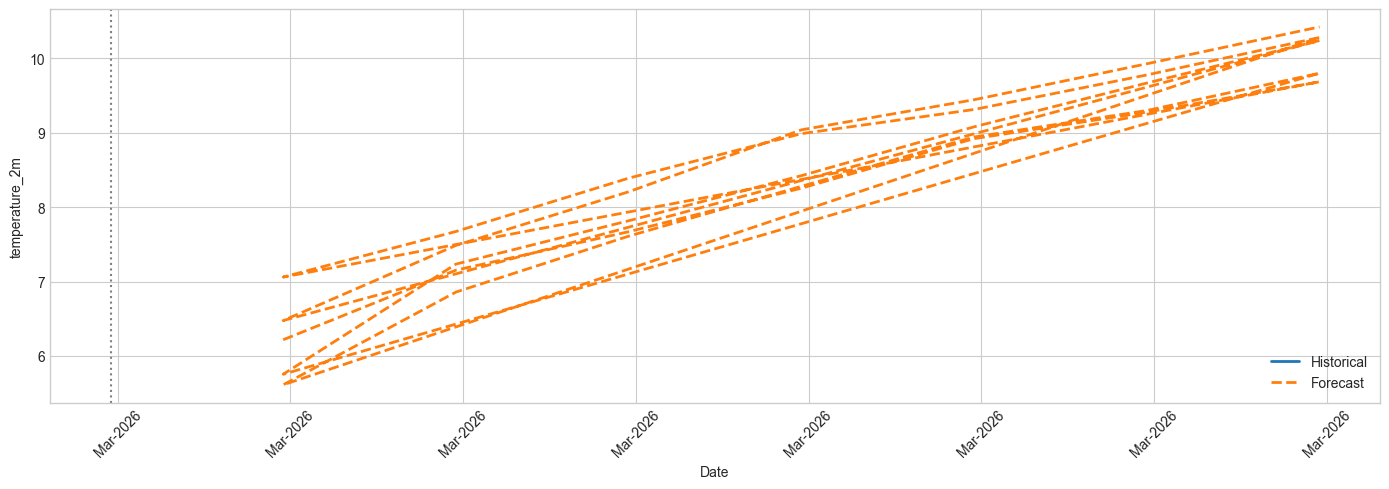

In [140]:
# 12. Visualisations (Optional)

# Feature Importance
plt.figure(figsize=(10, 6))
top = RESULTS['importance'].head(15).sort_values('Importance')
plt.barh(top['Feature'], top['Importance'], color=plt.cm.Blues(np.linspace(0.4, 0.9, len(top))))
plt.xlabel('Importance')
plt.title('Feature Importance')
plt.tight_layout()
plt.show()

# Actual vs Predicted
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(y_test, y_pred_test, alpha=0.5, s=10)
lims = [min(y_test.min(), y_pred_test.min()), max(y_test.max(), y_pred_test.max())]
axes[0].plot(lims, lims, 'r--')
axes[0].set_xlabel('Actual')
axes[0].set_ylabel('Predicted')
axes[1].hist(test['error'], bins=50, edgecolor='black', alpha=0.7)
axes[1].axvline(0, color='red', linestyle='--')
axes[1].set_xlabel('Error')
plt.tight_layout()
plt.show()

# Future Forecast
if CONFIG['generate_future_forecast']:
     plt.figure(figsize=(14, 5))
     hist = df.tail(100)
     plt.plot(hist[CONFIG['datetime_col']], hist[target_col], label='Historical', linewidth=2)
     fc = RESULTS['future_forecast']
     plt.plot(pd.to_datetime(fc['datetime']), fc['predicted'], label='Forecast', linestyle='--', linewidth=2)
     plt.axvline(df[CONFIG['datetime_col']].max(), color='grey', linestyle=':')
     plt.xlabel('Date')
     plt.ylabel(target_col)
     plt.legend()
     plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b-%Y'))
     plt.xticks(rotation=45)
     plt.tight_layout()
     plt.show()

In [141]:
# #### 13. Save Results (Optional)

# %%
# # Save Predictions
# output_path = Path(CONFIG['output_path'])
# output_path.mkdir(parents=True, exist_ok=True)
# save_cols = [c for c in [CONFIG['datetime_col'], 'date_formatted', target_col, 'predicted', 'error'] + CONFIG['encode_cols'] if c in test.columns]
# test[save_cols].to_csv(output_path / CONFIG['output_file'], index=False)

# %%
# # Save Future Forecast
# if CONFIG['generate_future_forecast']:
#     save_cols = [c for c in ['datetime', 'date_formatted', 'predicted'] + CONFIG['analysis_group_cols'] if c in RESULTS['future_forecast'].columns]
#     RESULTS['future_forecast'][save_cols].to_csv(output_path / CONFIG['future_forecast_file'], index=False)

# %% [markdown]
# ---
# #### Quick Reference
# 
# **Column Mapping**
# ```python
# 'column_mapping': {'Transaction Date': 'datetime', 'Sales Amount': 'sales'}
# ```
# 
# **Date Formats**
# ```python
# None              # Auto-detect
# '%Y-%m-%d'        # 2025-01-15
# '%d/%m/%Y'        # 15/01/2025 (UK)
# '%m/%d/%Y'        # 01/15/2025 (US)
# ```
# 
# **Calculated Targets**
# ```python
# 'unit_price * quantity'              # Revenue
# 'revenue - cost'                     # Profit
# '(revenue - cost) / revenue * 100'   # Margin %
# ```
# 
# **Lag Features (Daily Data)**
# ```python
# 'target_lag_1': 1      # Yesterday
# 'target_lag_7': 7      # Last week
# 'target_lag_30': 30    # Last month
# 'target_lag_365': 365  # Last year
# ```
# 
# **Lag Features (Monthly Data)**
# ```python
# 'target_lag_1': 1      # Last month
# 'target_lag_3': 3      # Last quarter
# 'target_lag_12': 12    # Last year
# ```
# 
# **Forecast Horizons**
# ```python
# 'forecast_horizon': 7,  'forecast_unit': 'days'     # 1 week
# 'forecast_horizon': 30, 'forecast_unit': 'days'     # 1 month
# 'forecast_horizon': 18, 'forecast_unit': 'months'   # 1.5 years
# 'forecast_horizon': 6,  'forecast_unit': 'years'    # 6 years
# ```